<a href="https://colab.research.google.com/github/BasmahFuad/Deep_Learning/blob/main/Assigment_1_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ARTI 502 — Assignment 1: Training and Testing a Neural Network

MNIST digit classification with PyTorch. This notebook covers dataset inspection, a fully connected network with one hidden layer, SGD training, testing, learning-rate/momentum experiments, and architecture comparisons. Run cells from top to bottom.


## 1. Import libraries and choose device
PyTorch and torchvision provide the model, dataset, and training utilities.


In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)


PyTorch: 2.11.0+cpu
Device: cpu


## 2. Download and load MNIST
The official PyTorch MNIST training split contains 60,000 images and the test split contains 10,000. (Some assignment text says 50,000 for training.)


In [2]:
transform = transforms.ToTensor()
trainset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
testset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

BATCH_SIZE = 32
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False)
print(f"Train images: {len(trainset):,}; test images: {len(testset):,}")


100%|██████████| 9.91M/9.91M [00:01<00:00, 6.53MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 155kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.47MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.22MB/s]

Train images: 60,000; test images: 10,000


## 3. Inspect and visualize a batch
Images have shape `(batch, channels, height, width)`. Labels are digit classes 0–9.


Image batch shape: (32, 1, 28, 28)
Label batch shape: (32,)
One image shape: (1, 28, 28)


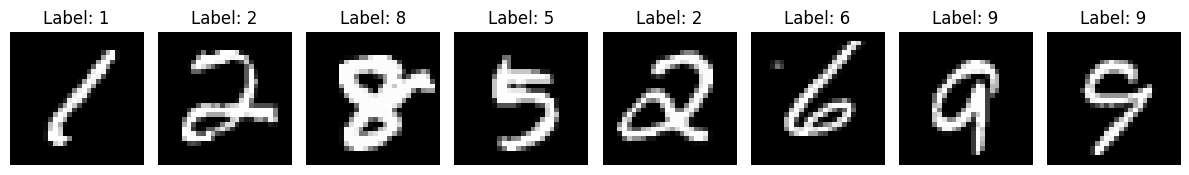

In [3]:
images, labels = next(iter(trainloader))
print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))
print("One image shape:", tuple(images[0].shape))

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, image, label in zip(axes, images[:8], labels[:8]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 4. Define the required simple neural network
Flatten each image from `1 × 28 × 28` to `784`, then use one fully connected hidden layer, ReLU, and a 10-class output layer. `hidden_sizes` also lets the later architecture experiments compare deeper/wider networks.


In [4]:
class SimpleNN(nn.Module):
    def __init__(self, hidden_sizes=(128,)):
        super().__init__()
        layers = []
        input_size = 28 * 28
        for hidden_size in hidden_sizes:
            layers.extend([nn.Linear(input_size, hidden_size), nn.ReLU()])
            input_size = hidden_size
        layers.append(nn.Linear(input_size, 10))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        return self.network(x)

model = SimpleNN(hidden_sizes=(128,)).to(device)
print(model)
print("Flattened input size:", torch.flatten(images, start_dim=1).shape)


SimpleNN(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)
Flattened input size: torch.Size([32, 784])


## 5. Training and evaluation functions
Training uses `CrossEntropyLoss` and stochastic gradient descent with configurable learning rate and momentum. It prints epoch, batch, loss, and running accuracy, and returns loss/accuracy history for plotting.


In [5]:
criterion = nn.CrossEntropyLoss()

def train_model(model, dataloader, epochs=5, learning_rate=0.01, momentum=0.9, verbose=True):
    model = model.to(device)
    optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)
    history = {"loss": [], "accuracy": []}
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0
        for batch_idx, (batch_images, batch_labels) in enumerate(dataloader, start=1):
            batch_images, batch_labels = batch_images.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            correct += (outputs.argmax(dim=1) == batch_labels).sum().item()
            total += batch_labels.size(0)
            if verbose and (batch_idx == 1 or batch_idx % 100 == 0 or batch_idx == len(dataloader)):
                print(f"Epoch {epoch+1}/{epochs} | Batch {batch_idx}/{len(dataloader)} | Loss {loss.item():.4f} | Accuracy {100*correct/total:.2f}%")
        history["loss"].append(total_loss / len(dataloader))
        history["accuracy"].append(100 * correct / total)
        if verbose:
            print(f"Epoch summary — loss: {history['loss'][-1]:.4f}, accuracy: {history['accuracy'][-1]:.2f}%")
    return history

@torch.no_grad()
def evaluate(model, dataloader):
    model.eval()
    correct, total, total_loss = 0, 0, 0.0
    for batch_images, batch_labels in dataloader:
        batch_images, batch_labels = batch_images.to(device), batch_labels.to(device)
        outputs = model(batch_images)
        total_loss += criterion(outputs, batch_labels).item()
        correct += (outputs.argmax(dim=1) == batch_labels).sum().item()
        total += batch_labels.size(0)
    return total_loss / len(dataloader), 100 * correct / total


## 6. Train the baseline network
The default is five epochs. Increase `EPOCHS` if you have time/resources; training on a GPU is faster.


Epoch 1/5 | Batch 1/1875 | Loss 2.3061 | Accuracy 3.12%
Epoch 1/5 | Batch 100/1875 | Loss 0.6879 | Accuracy 61.66%
Epoch 1/5 | Batch 200/1875 | Loss 0.2378 | Accuracy 73.75%
Epoch 1/5 | Batch 300/1875 | Loss 0.5902 | Accuracy 78.04%
Epoch 1/5 | Batch 400/1875 | Loss 0.8732 | Accuracy 80.92%
Epoch 1/5 | Batch 500/1875 | Loss 0.2426 | Accuracy 82.69%
Epoch 1/5 | Batch 600/1875 | Loss 0.4045 | Accuracy 83.91%
Epoch 1/5 | Batch 700/1875 | Loss 0.4145 | Accuracy 84.67%
Epoch 1/5 | Batch 800/1875 | Loss 0.2491 | Accuracy 85.55%
Epoch 1/5 | Batch 900/1875 | Loss 0.1633 | Accuracy 86.17%
Epoch 1/5 | Batch 1000/1875 | Loss 0.1379 | Accuracy 86.73%
Epoch 1/5 | Batch 1100/1875 | Loss 0.1190 | Accuracy 87.16%
Epoch 1/5 | Batch 1200/1875 | Loss 0.3147 | Accuracy 87.60%
Epoch 1/5 | Batch 1300/1875 | Loss 0.3962 | Accuracy 87.94%
Epoch 1/5 | Batch 1400/1875 | Loss 0.2528 | Accuracy 88.33%
Epoch 1/5 | Batch 1500/1875 | Loss 0.3256 | Accuracy 88.64%
Epoch 1/5 | Batch 1600/1875 | Loss 0.1870 | Accuracy 

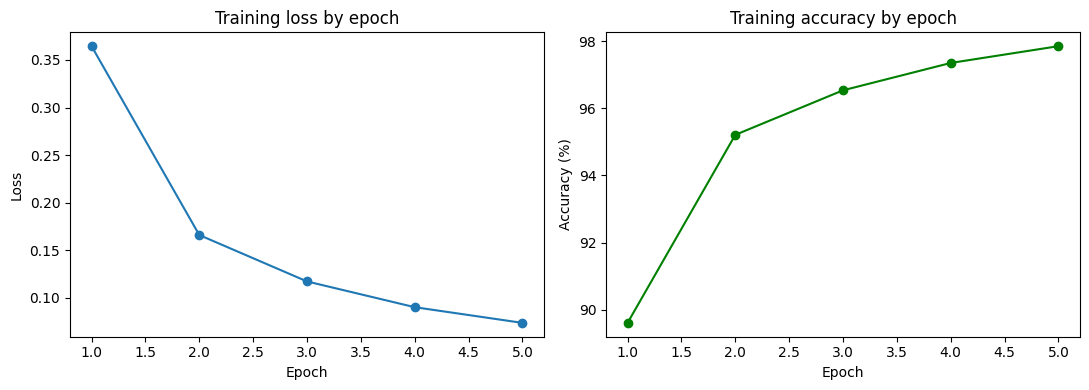

In [6]:
EPOCHS = 5
model = SimpleNN(hidden_sizes=(128,)).to(device)
history = train_model(model, trainloader, epochs=EPOCHS, learning_rate=0.01, momentum=0.9)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, EPOCHS+1), history["loss"], marker="o")
axes[0].set(title="Training loss by epoch", xlabel="Epoch", ylabel="Loss")
axes[1].plot(range(1, EPOCHS+1), history["accuracy"], marker="o", color="green")
axes[1].set(title="Training accuracy by epoch", xlabel="Epoch", ylabel="Accuracy (%)")
plt.tight_layout()
plt.show()


## 7. Test the network and inspect predictions


Test loss: 0.0846 | Test accuracy: 97.35%


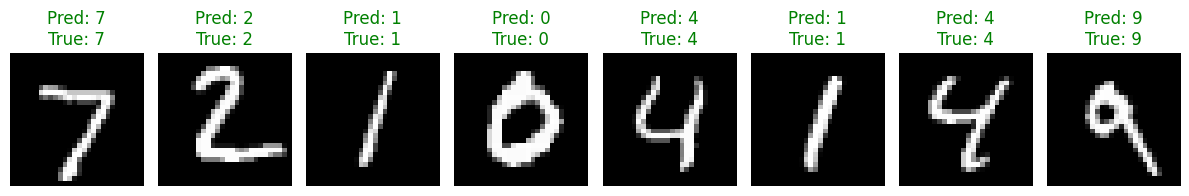

In [7]:
test_loss, test_accuracy = evaluate(model, testloader)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.2f}%")

model.eval()
images, labels = next(iter(testloader))
with torch.no_grad():
    predictions = model(images.to(device)).argmax(dim=1).cpu()
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, image, label, prediction in zip(axes, images[:8], labels[:8], predictions[:8]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Pred: {prediction.item()}\nTrue: {label.item()}", color="green" if prediction.item() == label.item() else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 8. Tune learning rate and momentum
This compact comparison trains each setting for two epochs on a fixed 12,000-example subset to keep the experiments practical. The baseline above uses the full training set. Review the results table and, if needed, increase `TUNING_EPOCHS` or use the full set for stronger comparisons.


In [8]:
TUNING_EPOCHS = 2
TUNING_SAMPLES = 12000
tuning_set = Subset(trainset, range(TUNING_SAMPLES))
tuning_loader = DataLoader(tuning_set, batch_size=BATCH_SIZE, shuffle=True)

parameter_results = []
for lr in (0.01, 0.05):
    for mom in (0.0, 0.9):
        candidate = SimpleNN((128,)).to(device)
        train_model(candidate, tuning_loader, epochs=TUNING_EPOCHS, learning_rate=lr, momentum=mom, verbose=False)
        loss, accuracy = evaluate(candidate, testloader)
        parameter_results.append({"learning_rate": lr, "momentum": mom, "test_loss": loss, "test_accuracy": accuracy})
        print(f"lr={lr}, momentum={mom} -> test loss={loss:.4f}, accuracy={accuracy:.2f}%")
best_parameters = min(parameter_results, key=lambda row: (row["test_loss"], -row["test_accuracy"]))
print("Best tested parameters:", best_parameters)


lr=0.01, momentum=0.0 -> test loss=0.7044, accuracy=83.84%
lr=0.01, momentum=0.9 -> test loss=0.3031, accuracy=91.31%
lr=0.05, momentum=0.0 -> test loss=0.3387, accuracy=90.34%
lr=0.05, momentum=0.9 -> test loss=0.2015, accuracy=93.80%
Best tested parameters: {'learning_rate': 0.05, 'momentum': 0.9, 'test_loss': 0.20148032533150678, 'test_accuracy': 93.8}


## 9. Compare model architectures
Compare one hidden layer with different widths and a two-hidden-layer model. Experiments use the same compact subset and epoch count; the selected model is based on test loss (with accuracy as a tie-breaker).


In [9]:
architecture_candidates = [(64,), (128,), (256,), (128, 64)]
architecture_results = []
for sizes in architecture_candidates:
    candidate = SimpleNN(hidden_sizes=sizes).to(device)
    train_model(candidate, tuning_loader, epochs=TUNING_EPOCHS, learning_rate=best_parameters["learning_rate"], momentum=best_parameters["momentum"], verbose=False)
    loss, accuracy = evaluate(candidate, testloader)
    architecture_results.append({"hidden_sizes": sizes, "test_loss": loss, "test_accuracy": accuracy})
    print(f"hidden_sizes={sizes} -> test loss={loss:.4f}, accuracy={accuracy:.2f}%")
best_architecture = min(architecture_results, key=lambda row: (row["test_loss"], -row["test_accuracy"]))
print("Best tested architecture:", best_architecture)


hidden_sizes=(64,) -> test loss=0.2571, accuracy=91.55%
hidden_sizes=(128,) -> test loss=0.2117, accuracy=93.50%
hidden_sizes=(256,) -> test loss=0.2144, accuracy=93.23%
hidden_sizes=(128, 64) -> test loss=0.2197, accuracy=93.59%
Best tested architecture: {'hidden_sizes': (128,), 'test_loss': 0.21173264217018462, 'test_accuracy': 93.5}


## 10. Retrain the selected configuration and save the model
The final model is trained on all training examples using the best settings observed above.


In [10]:
final_hidden_sizes = best_architecture["hidden_sizes"]
final_lr = best_parameters["learning_rate"]
final_momentum = best_parameters["momentum"]
final_model = SimpleNN(final_hidden_sizes).to(device)
final_history = train_model(final_model, trainloader, epochs=EPOCHS, learning_rate=final_lr, momentum=final_momentum)
final_loss, final_accuracy = evaluate(final_model, testloader)
print(f"Final test loss: {final_loss:.4f}; final test accuracy: {final_accuracy:.2f}%")
torch.save({"model_state_dict": final_model.state_dict(), "hidden_sizes": final_hidden_sizes, "learning_rate": final_lr,
            "momentum": final_momentum}, "mnist_simple_nn.pth")
print("Saved model weights to mnist_simple_nn.pth")


Epoch 1/5 | Batch 1/1875 | Loss 2.3252 | Accuracy 3.12%
Epoch 1/5 | Batch 100/1875 | Loss 0.5936 | Accuracy 71.75%
Epoch 1/5 | Batch 200/1875 | Loss 0.3286 | Accuracy 80.09%
Epoch 1/5 | Batch 300/1875 | Loss 0.3086 | Accuracy 84.08%
Epoch 1/5 | Batch 400/1875 | Loss 0.1244 | Accuracy 86.04%
Epoch 1/5 | Batch 500/1875 | Loss 0.2819 | Accuracy 87.28%
Epoch 1/5 | Batch 600/1875 | Loss 0.2063 | Accuracy 88.32%
Epoch 1/5 | Batch 700/1875 | Loss 0.0313 | Accuracy 89.02%
Epoch 1/5 | Batch 800/1875 | Loss 0.1372 | Accuracy 89.66%
Epoch 1/5 | Batch 900/1875 | Loss 0.2646 | Accuracy 90.17%
Epoch 1/5 | Batch 1000/1875 | Loss 0.4152 | Accuracy 90.62%
Epoch 1/5 | Batch 1100/1875 | Loss 0.1053 | Accuracy 91.00%
Epoch 1/5 | Batch 1200/1875 | Loss 0.1658 | Accuracy 91.26%
Epoch 1/5 | Batch 1300/1875 | Loss 0.0484 | Accuracy 91.60%
Epoch 1/5 | Batch 1400/1875 | Loss 0.1470 | Accuracy 91.84%
Epoch 1/5 | Batch 1500/1875 | Loss 0.1810 | Accuracy 92.06%
Epoch 1/5 | Batch 1600/1875 | Loss 0.2747 | Accuracy 

## Submission checklist
- Run all cells from top to bottom and keep the output visible.
- Capture screenshots for dataset loading, tensor shape/visualization, model source, training debug/plots, test predictions, and tuning results.
- Save/submit the Python source code and add your group/member details and GitHub repository link to the assignment document.
